In [1]:
import argparse
import sys
import contextlib
import logging
import os
import time
import traceback
from pathlib import Path
 
import numpy as np
import pandas as pd
import torch
from flwr.simulation import run_simulation
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
 
import config
import fl_basic4 as fl          # <- ganti jika nama file strategy/client-mu berbeda
from dataset import DROP_COLS, TARGET
from model import build_model
 
# ============================================================
# 0. KONFIGURASI RUNNER
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
ALGOS = ['fedavg', 'fedprox', 'fedavgm', 'fedadam', 'fedpairwise']
BASELINE = 'fedavg'                      # pembanding untuk uji berpasangan
ORIG_OUT_DIR = Path(config.OUT_DIR)      # folder induk output = ORIG_OUT_DIR.parent
ORIG_SEED = int(config.SEED)
 
SEEDS = [42, 0, 123, 1337, 3407]
 
# metrik: 'ap' = Average Precision (ringkasan area di bawah PR curve)
METRIC_COLS = ['acc', 'prec', 'rec', 'f1', 'auc', 'ap',
               'f1_macro', 'f1_std_klien', 'total_MB', 'waktu_s']
PAIRED_METRICS = ('f1', 'auc', 'ap')
 
# ---- logging ----
VERBOSE = False                          # True = semua print tampil di konsol
LOG_DIR = ORIG_OUT_DIR.parent
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_FLWR = LOG_DIR / 'flwr.log'
LOG_PRINTS = LOG_DIR / 'prints.log'
 
 
def setup_flwr_logging():
    """Console Flower hanya WARNING+; detail penuh ke file. Aman dipanggil berulang."""
    lg = logging.getLogger("flwr")
    for h in lg.handlers:
        if not isinstance(h, logging.FileHandler):
            h.setLevel(logging.WARNING)
    if not any(isinstance(h, logging.FileHandler) for h in lg.handlers):
        fh = logging.FileHandler(LOG_FLWR, encoding="utf-8")
        fh.setLevel(logging.INFO)
        fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
        lg.addHandler(fh)
    lg.setLevel(logging.INFO)
 
 
@contextlib.contextmanager
def quiet(logfile=None):
    """Alihkan print() ke file. Dinonaktifkan bila VERBOSE."""
    if VERBOSE:
        yield
        return
    with open(logfile or LOG_PRINTS, "a", encoding="utf-8") as f, \
            contextlib.redirect_stdout(f):
        yield
 
 
setup_flwr_logging()
 
 
# %%
# ============================================================
# 1. DATASET, MODUL & RINGKASAN DATA
# ============================================================
def setup_dataset():
    """Arahkan config ke folder dataset dan buang cache data lama."""
    if not CLIENT_DIR.is_dir():
        sys.exit(f"Folder dataset tidak ditemukan: {CLIENT_DIR}")
    config.CLIENT_DIR = CLIENT_DIR
    os.environ['FL_CLIENT_DIR'] = str(CLIENT_DIR)
    try:
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    clear = getattr(fl.load_data, 'cache_clear', None)
    if clear:
        clear()
    n_item = sum(1 for _ in CLIENT_DIR.iterdir())
    print(f"Dataset : {CLIENT_DIR} ({n_item} item)")
 
 
def show_modules():
    print(f"Modul FL: {fl.__name__} ({Path(fl.__file__).name})")
    cls = getattr(fl, 'FedCosinePairwise', None)
    if cls is not None:
        print(f"Agregasi pairwise dari modul: {cls.__module__}")
 
 
def available_algos(algos):
    known = getattr(fl, 'ALGOS', algos)
    ok = [a for a in algos if a in known]
    skip = [a for a in algos if a not in ok]
    if skip:
        print(f"[lewati] tidak ada di {fl.__name__}.ALGOS: {skip}")
    return ok
 
 
def data_summary():
    clients, scaler, feature_names = fl.load_data()
    n_clients = len(clients)
    n_fitur = fl.get_in_dim()
    assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
 
    print("=" * 50)
    print(f"Jumlah client (state) : {n_clients}")
    print(f"Daftar state          : {fl.state_list()}")
    print(f"Target                : {TARGET}")
    print(f"Kolom dibuang         : {DROP_COLS}")
    print(f"Jumlah fitur          : {n_fitur}")
    print(f"Jumlah ronde          : {config.NUM_ROUNDS}")
    print(f"Client dilatih/ronde  : "
          f"{max(1, round(config.FRACTION_FIT * n_clients))} dari {n_clients}")
    print(f"Local epochs          : {config.LOCAL_EPOCHS}")
    print("=" * 50)
    for i, nama in enumerate(feature_names, 1):
        print(f"{i:>3}. {nama}")
 
    rows = {st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    } for st, c in clients.items()}
 
    ringkas = pd.DataFrame(rows).T
    ringkas.index.name = 'state'
    for s in ('train', 'val', 'test'):
        ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
 
    total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
    for s in ('train', 'val', 'test'):
        total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
    ringkas.loc['TOTAL'] = total
 
    print("\nRingkasan per client:")
    print(ringkas.to_string())
 
    total_train = sum(len(c['y_train_t']) for c in clients.values())
    print("\nscaler.n_samples_seen_ vs total train:",
          scaler.n_samples_seen_, total_train, "(harus sama)")
    return n_clients

2026-10-22 14:15:13,453	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:

# %%
# ============================================================
# 2. JALANKAN SATU (ALGORITMA, SEED)
# ============================================================
def run_algo(algo, seed, n_clients, out_root):
    """Simulasi FL untuk satu algoritma & seed; output ke out_root/out_<algo>_s<seed>."""
    config.SEED = seed
    os.environ['FL_SEED'] = str(seed)
    config.OUT_DIR = out_root / f'out_{algo}_s{seed}'
    config.ensure_out_dir()
    for nama in ('final_params.npz', 'ronde_log.csv'):
        (config.OUT_DIR / nama).unlink(missing_ok=True)
    print(f"\n########## {algo} | seed {seed} ##########")
    setup_flwr_logging()                    # jaga-jaga bila handler di-reset
    with quiet():                           # print() internal -> prints.log
        run_simulation(
            server_app=fl.make_server_app(algo),
            client_app=fl.make_client_app(),
            num_supernodes=n_clients,
            backend_config={"client_resources": {"num_cpus": 1, "num_gpus": 0.0}},
        )
 
 
def load_global_model():
    path = config.OUT_DIR / 'final_params.npz'
    if not path.exists():
        raise FileNotFoundError(
            f"{path} tidak ada: simulasi gagal sebelum ada ronde yang selesai. "
            f"Cek {config.OUT_DIR / 'client_error.log'}")
    d = np.load(path)
    w = [d[f'arr_{i}'] for i in range(len(d.files))]
    m = build_model(fl.get_in_dim(), seed=config.SEED).to(config.DEVICE)
    fl.set_weights(m, w)
    return m
 
 
# %%
# ============================================================
# 2b. METRIK DIAGNOSTIK: AUC-ROC, PR CURVE / AP
# ============================================================
def _to_prob(out):
    """Ubah output model (logit / prob / 2 kelas) menjadi P(kelas=1), shape (n,)."""
    out = np.asarray(out, dtype=np.float64)
    if out.ndim == 2 and out.shape[1] == 2:
        if out.min() < 0 or out.max() > 1 or not np.allclose(out.sum(1), 1, atol=1e-3):
            e = np.exp(out - out.max(1, keepdims=True))
            out = e / e.sum(1, keepdims=True)
        return out[:, 1]
    out = out.reshape(-1)
    if out.min() < 0.0 or out.max() > 1.0:          # logit -> sigmoid
        out = 1.0 / (1.0 + np.exp(-out))
    return out
 
 
def predict_proba_clients(model, split='test'):
    """Probabilitas prediksi & label per client. Asumsi kunci data: X_<split>_t, y_<split>_t."""
    clients, _, _ = fl.load_data()
    model.eval()
    ys, ps = {}, {}
    with torch.no_grad():
        for st, c in clients.items():
            xk, yk = f'X_{split}_t', f'y_{split}_t'
            if xk not in c:
                raise KeyError(f"Kunci '{xk}' tidak ada di data client. "
                               f"Kunci tersedia: {list(c.keys())}  -> sesuaikan xk.")
            out = model(c[xk].to(config.DEVICE)).detach().cpu().numpy()
            ps[st] = _to_prob(out)
            ys[st] = c[yk].detach().cpu().numpy().reshape(-1).astype(int)
    return ys, ps
 
 
def diagnostic_metrics(model, split='test'):
    """AUC-ROC & AP gabungan + AP/AUC per state + titik kurva ROC & PR gabungan."""
    ys, ps = predict_proba_clients(model, split)
    y_all = np.concatenate(list(ys.values()))
    p_all = np.concatenate(list(ps.values()))
 
    def _safe(fn, y, p):
        return float(fn(y, p)) if 0 < y.sum() < len(y) else float('nan')
 
    per_state = pd.DataFrame({
        st: {'auc': _safe(roc_auc_score, ys[st], ps[st]),
             'ap': _safe(average_precision_score, ys[st], ps[st]),
             'prevalensi': float(ys[st].mean())}
        for st in ys}).T
    per_state.index.name = 'state'
 
    fpr, tpr, _ = roc_curve(y_all, p_all)
    prec, rec, _ = precision_recall_curve(y_all, p_all)
    return {
        'auc': _safe(roc_auc_score, y_all, p_all),
        'ap': _safe(average_precision_score, y_all, p_all),
        'prevalensi': float(y_all.mean()),          # garis dasar PR (AP acak = prevalensi)
        'per_state': per_state,
        'roc': (fpr, tpr),
        'pr': (rec, prec),
    }
 
 
def run_single(algo, seeds, n_clients, out_root):
    try:
        for seed in seeds:
            run_algo(algo, seed, n_clients, out_root)
 
            rep, ronde = fl.bandwidth_report()
            print(ronde.round(4).to_string(index=False))
 
            model = load_global_model()
            df_test = fl.evaluate_on_clients(model, split='test')
            print(df_test.round(4).to_string())
            print(fl.summarize(df_test).round(4).to_string())
            print("Pooled:", fl.evaluate_pooled(model, split='test'))
 
            diag = diagnostic_metrics(model, 'test')
            print(f"AUC-ROC gabungan : {diag['auc']:.4f}")
            print(f"AP gabungan      : {diag['ap']:.4f}  "
                  f"(garis dasar acak = prevalensi {diag['prevalensi']:.4f})")
            print("AUC / AP per state:")
            print(diag['per_state'].round(4).to_string())
    finally:
        config.SEED = ORIG_SEED
 
 
# %%
from sklearn.metrics import auc as sk_auc

def collect_result(secs):
    model   = load_global_model()
    pooled  = fl.evaluate_pooled(model, split='test')
    df_test = fl.evaluate_on_clients(model, split='test')
    ronde   = pd.read_csv(config.OUT_DIR / 'ronde_log.csv')
    bw, _   = fl.bandwidth_report(verbose=False)
    diag    = diagnostic_metrics(model, 'test')

    # --- log validasi per ronde (aman bila kosong / semua NaN) ---
    f1 = ronde['f1'].astype(float).reset_index(drop=True)
    ronde = ronde.reset_index(drop=True)
    val_akhir = float(f1.iloc[-1]) if len(f1) else float('nan')
    if f1.notna().any():
        best = f1.idxmax()
        val_best, best_round = float(f1[best]), int(ronde.loc[best, 'round'])
    else:
        val_best, best_round = float('nan'), -1

    # --- PR-AUC trapesium (selain AP) ---
    rec, prec = diag['pr']
    pr_auc = float(sk_auc(rec, prec)) if len(rec) > 1 else float('nan')

    # --- metrik pooled: hanya nilai numerik ---
    pooled_num = {k: float(v) for k, v in pooled.items()
                  if np.isscalar(v) and v is not None}

    row = {
        **pooled_num,
        'auc':            diag['auc'],      # selalu dari diagnostic (konsisten)
        'ap':             diag['ap'],       # Average Precision
        'prauc':          pr_auc,           # PR-AUC (trapesium), alias agar mudah dicari
        'prevalensi':     diag['prevalensi'],
        'f1_macro_klien': float(df_test['f1'].mean()),   # rata-rata F1 antar klien
        'f1_std_klien':   float(df_test['f1'].std()),
        'val_f1_akhir':   val_akhir,
        'val_f1_terbaik': val_best,
        'ronde_terbaik':  best_round,
        'total_MB':       float(bw['total_MB']),
        'waktu_s':        round(secs, 1),
    }
    return row, df_test['f1'], ronde, diag
 
 
def _fmt(mean, std, n, nd=4):
    if n < 2 or pd.isna(std):
        return f"{mean:.{nd}f}"
    return f"{mean:.{nd}f} ± {std:.{nd}f}"
 
 
def summarize_seeds(per_seed):
    cols = [c for c in METRIC_COLS if c in per_seed.columns]
    g = per_seed.groupby(level='algoritma')[cols]
    mean, std = g.mean(), g.std()
    n = g.size().rename('n_seed')
 
    num = pd.concat({'mean': mean, 'std': std}, axis=1)
    num.columns = [f'{c}_{stat}' for stat, c in num.columns]
    num.insert(0, 'n_seed', n)
    num = num.sort_values('f1_mean', ascending=False)
 
    tampil = pd.DataFrame(index=num.index)
    tampil['n_seed'] = num['n_seed']
    for c in cols:
        nd = 2 if c in ('total_MB', 'waktu_s') else 4
        tampil[c] = [_fmt(num.loc[a, f'{c}_mean'], num.loc[a, f'{c}_std'],
                          int(num.loc[a, 'n_seed']), nd) for a in num.index]
    return num, tampil
 
 
def _pvalue(d):
    if len(d) < 3 or float(d.std()) == 0.0:
        return float('nan')
    try:
        from scipy import stats
    except ImportError:
        return float('nan')
    return float(stats.ttest_1samp(d, 0.0).pvalue)
 
 
def paired_vs_baseline(per_seed, baseline, metrics=PAIRED_METRICS):
    algos = list(per_seed.index.get_level_values('algoritma').unique())
    if baseline not in algos:
        return None
    base = per_seed.xs(baseline, level='algoritma')
    out = []
    for algo in algos:
        if algo == baseline:
            continue
        cur = per_seed.xs(algo, level='algoritma')
        seeds = base.index.intersection(cur.index)
        if len(seeds) == 0:
            continue
        row = {'algoritma': algo, 'n_seed': len(seeds)}
        for m in metrics:
            d = (cur.loc[seeds, m] - base.loc[seeds, m]).astype(float)
            row[f'd{m}_mean'] = float(d.mean())
            row[f'd{m}_std'] = float(d.std()) if len(d) > 1 else float('nan')
            row[f'{m}_menang'] = f"{int((d > 0).sum())}/{len(d)}"
            row[f'{m}_p'] = _pvalue(d)
        out.append(row)
    return pd.DataFrame(out).set_index('algoritma') if out else None
 
 
def _get_plt():
    try:
        import matplotlib
        if 'ipykernel' not in sys.modules:
            matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        return plt
    except ImportError:
        print("[lewati grafik] matplotlib belum terpasang (pip install matplotlib)")
        return None
 
 
def _finish(plt, fig, out_path):
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    print(f"Grafik disimpan: {out_path}")
    if 'ipykernel' in sys.modules:
        plt.show()
    else:
        plt.close(fig)
 
 
def plot_curves(kurva, out_path):
    """F1 & AUC validasi per ronde: rata-rata antar seed, pita = ± std."""
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), ronde in kurva.items():
        per_algo.setdefault(algo, []).append(ronde)
 
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, col, judul in zip(axes, ('f1', 'auc'), ('F1 validasi', 'AUC validasi')):
        for algo, rs in per_algo.items():
            m = pd.concat([r.set_index('round')[col] for r in rs], axis=1)
            mu, sd = m.mean(axis=1), m.std(axis=1)
            ax.plot(mu.index, mu.values, marker='o', ms=3,
                    label=f'{algo} (n={len(rs)})')
            if len(rs) > 1:
                ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values, alpha=0.15)
        ax.set_xlabel('Ronde')
        ax.set_ylabel(judul)
        ax.set_title(f'{judul} per ronde (rata-rata ± std antar seed)')
        ax.grid(alpha=0.3)
    axes[0].legend()
    _finish(plt, fig, out_path)
 
 
def plot_roc_pr(diags, out_path):
    """Kurva ROC & PR test gabungan: rata-rata antar seed pada grid sama, pita = ± std."""
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), d in diags.items():
        per_algo.setdefault(algo, []).append(d)
 
    grid = np.linspace(0, 1, 201)
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
 
    for algo, ds in per_algo.items():
        tprs = np.array([np.interp(grid, *d['roc']) for d in ds])
        # PR: recall menurun -> balik urutan agar np.interp valid
        precs = np.array([np.interp(grid, d['pr'][0][::-1], d['pr'][1][::-1]) for d in ds])
        auc_m = np.nanmean([d['auc'] for d in ds])
        ap_m = np.nanmean([d['ap'] for d in ds])
 
        mu = tprs.mean(0)
        ax_roc.plot(grid, mu, label=f'{algo} (AUC={auc_m:.3f})')
        mu_p = precs.mean(0)
        ax_pr.plot(grid, mu_p, label=f'{algo} (AP={ap_m:.3f})')
        if len(ds) > 1:
            sd = tprs.std(0, ddof=1)
            ax_roc.fill_between(grid, mu - sd, mu + sd, alpha=0.12)
            sd_p = precs.std(0, ddof=1)
            ax_pr.fill_between(grid, mu_p - sd_p, mu_p + sd_p, alpha=0.12)
 
    prev = np.mean([d['prevalensi'] for ds in per_algo.values() for d in ds])
    ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='acak')
    ax_pr.axhline(prev, color='k', ls='--', lw=1, label=f'acak (prevalensi={prev:.3f})')
 
    ax_roc.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
               title='Kurva ROC (test gabungan)')
    ax_pr.set(xlabel='Recall', ylabel='Precision',
              title='Kurva Precision-Recall (test gabungan)', ylim=(0, 1.02))
    for ax in (ax_roc, ax_pr):
        ax.grid(alpha=0.3)
        ax.legend(loc='best', fontsize=8)
    _finish(plt, fig, out_path)
 
 
def run_compare(algos, seeds, n_clients, out_root):
    rows, f1_klien, kurva, diags = {}, {}, {}, {}
    total_run = len(algos) * len(seeds)
    print(f"\nKomparasi: {len(algos)} algoritma x {len(seeds)} seed = {total_run} run")
    print(f"Seed: {seeds}")
    print(f"Log detail: {LOG_FLWR} | {LOG_PRINTS}")
 
    try:
        for seed in seeds:
            for algo in algos:
                t0 = time.perf_counter()
                try:
                    run_algo(algo, seed, n_clients, out_root)
                    row, f1c, ronde, diag = collect_result(time.perf_counter() - t0)
                except Exception:
                    print(f"[GAGAL] {algo} seed {seed}:\n{traceback.format_exc()}")
                    continue
                key = (algo, seed)
                rows[key], f1_klien[key], kurva[key], diags[key] = row, f1c, ronde, diag
                print(f"[selesai] {algo} s{seed}: F1 test {row['f1']:.4f} | "
                      f"AUC {row['auc']:.4f} | AP {row['ap']:.4f} | "
                      f"{row['total_MB']:.2f} MB | {row['waktu_s']} s")
    finally:
        config.SEED = ORIG_SEED
 
    if not rows:
        sys.exit("Tidak ada run yang berhasil.")
 
    idx = pd.MultiIndex.from_tuples(list(rows.keys()), names=['algoritma', 'seed'])
    per_seed = pd.DataFrame(list(rows.values()), index=idx)
 
    num, tampil = summarize_seeds(per_seed)
    berpasangan = paired_vs_baseline(per_seed, BASELINE)
 
    per_klien = pd.DataFrame({
        algo: pd.concat([f1_klien[k] for k in f1_klien if k[0] == algo], axis=1).mean(axis=1)
        for algo in num.index
    })
    per_klien.loc['MAKRO'] = per_klien.mean()
 
    # AP per state (rata-rata antar seed)
    ap_klien = pd.DataFrame({
        algo: pd.concat([diags[k]['per_state']['ap'] for k in diags if k[0] == algo],
                        axis=1).mean(axis=1)
        for algo in num.index
    })
    ap_klien.loc['MAKRO'] = ap_klien.mean()
 
    print("\n" + "=" * 70)
    print("PERBANDINGAN AGREGASI  (rata-rata ± simpangan antar seed; urut F1)")
    print("=" * 70)
    print(tampil.to_string())
 
    print("\nHasil per seed (F1 | AUC | AP test gabungan):")
    print(per_seed[['f1', 'auc', 'ap']].round(4).unstack('seed').to_string())
 
    if berpasangan is not None:
        print(f"\nSelisih terhadap {BASELINE} pada seed yang sama "
              f"(positif = lebih baik dari {BASELINE}):")
        print(berpasangan.round(4).to_string())
        if int(berpasangan['n_seed'].min()) < 5:
            print("Catatan: dengan <5 seed uji-t lemah; jangan terlalu bergantung "
                  "pada p-value. Lihat kolom *_menang dan konsistensi arah selisih.")
    elif len(seeds) > 1:
        print(f"\n[uji berpasangan dilewati] baseline '{BASELINE}' tidak ikut/ gagal.")
 
    print("\nF1 test per state (rata-rata antar seed):")
    print(per_klien.round(4).to_string())
    print("\nAP test per state (rata-rata antar seed):")
    print(ap_klien.round(4).to_string())
 
    print(f"\nTerbaik F1 (rata-rata)    : {num['f1_mean'].idxmax()}")
    print(f"Terbaik AUC (rata-rata)   : {num['auc_mean'].idxmax()}")
    print(f"Terbaik AP (rata-rata)    : {num['ap_mean'].idxmax()}")
    if len(seeds) > 1:
        print(f"Paling stabil antar seed  : {num['f1_std'].idxmin()} (std F1 terkecil)")
    print(f"Paling merata antar state : {num['f1_std_klien_mean'].idxmin()}")
    mb = num['total_MB_mean']
    if (mb.max() - mb.min()) > 0.01 * mb.max():
        print(f"Bandwidth terkecil        : {mb.idxmin()}")
    else:
        print("Bandwidth                 : sama untuk semua algoritma (ukuran parameter sama)")
 
    out_root.mkdir(parents=True, exist_ok=True)
    per_seed.to_csv(out_root / 'perbandingan_per_seed.csv')
    num.to_csv(out_root / 'perbandingan_ringkasan.csv')
    per_klien.to_csv(out_root / 'perbandingan_f1_per_client.csv')
    ap_klien.to_csv(out_root / 'perbandingan_ap_per_client.csv')
    if berpasangan is not None:
        berpasangan.to_csv(out_root / 'perbandingan_berpasangan.csv')
    print(f"\nCSV disimpan di: {out_root}")
    plot_curves(kurva, out_root / 'kurva_validasi.png')
    plot_roc_pr(diags, out_root / 'kurva_roc_pr_test.png')
    return per_seed, num

Modul FL: fl_basic4 (fl_basic4.py)
Agregasi pairwise dari modul: aggregation4
Dataset : C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients (45 item)
Jumlah client (state) : 44
Daftar state          : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target                : _michd
Kolom dibuang         : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur          : 69
Jumlah ronde          : 10
Client dilatih/ronde  : 44 dari 44
Local epochs          : 5
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnka

[selesai] fedavg s42: F1 test 0.4648 | AUC 0.7357 | AP 0.4293 | 34.99 MB | 85.2 s

########## fedprox | seed 42 ##########


[selesai] fedprox s42: F1 test 0.4668 | AUC 0.7373 | AP 0.4322 | 34.99 MB | 158.9 s

########## fedavgm | seed 42 ##########


[selesai] fedavgm s42: F1 test 0.3757 | AUC 0.6487 | AP 0.3318 | 34.99 MB | 126.9 s

########## fedadam | seed 42 ##########


[selesai] fedadam s42: F1 test 0.4433 | AUC 0.7142 | AP 0.3859 | 34.99 MB | 132.0 s

########## fedpairwise | seed 42 ##########


...

[selesai] fedprox s3407: F1 test 0.4682 | AUC 0.7369 | AP 0.4276 | 34.99 MB | 87.6 s

########## fedavgm | seed 3407 ##########


(ClientAppActor pid=24996) WARNING :   Manually terminating ClientAppActor
(ClientAppActor pid=30612) WARNING :   Manually terminating ClientAppActor [repeated 7x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en/master/ray-observability/ray-logging.html#log-deduplication for more options.)


[selesai] fedavgm s3407: F1 test 0.2965 | AUC 0.5905 | AP 0.2618 | 34.99 MB | 70.5 s

########## fedadam | seed 3407 ##########


[selesai] fedadam s3407: F1 test 0.4428 | AUC 0.7130 | AP 0.3840 | 34.99 MB | 68.4 s

########## fedpairwise | seed 3407 ##########


[selesai] fedpairwise s3407: F1 test 0.4676 | AUC 0.7394 | AP 0.4340 | 34.99 MB | 71.4 s

PERBANDINGAN AGREGASI  (rata-rata ± simpangan antar seed; urut F1)
             n_seed              acc             prec              rec               f1              auc               ap     f1_std_klien      total_MB         waktu_s
algoritma                                                                                                                                                               
fedpairwise       5  0.7006 ± 0.0043  0.3728 ± 0.0038  0.6321 ± 0.0060  0.4690 ± 0.0017  0.7399 ± 0.0006  0.4371 ± 0.0019  0.0421 ± 0.0014  34.99 ± 0.00   84.24 ± 25.21
fedprox           5  0.6966 ± 0.0037  0.3692 ± 0.0026  0.6355 ± 0.0091  0.4670 ± 0.0009  0.7380 ± 0.0015  0.4328 ± 0.0033  0.0419 ± 0.0012  34.99 ± 0.00  119.36 ± 33.43
fedavg            5  0.6980 ± 0.0034  0.3697 ± 0.0025  0.6296 ± 0.0078  0.4658 ± 0.0008  0.7370 ± 0.0015  0.4308 ± 0.0035  0.0407 ± 0.0019  34.99 ± 0.00   95.70 ± 31.2

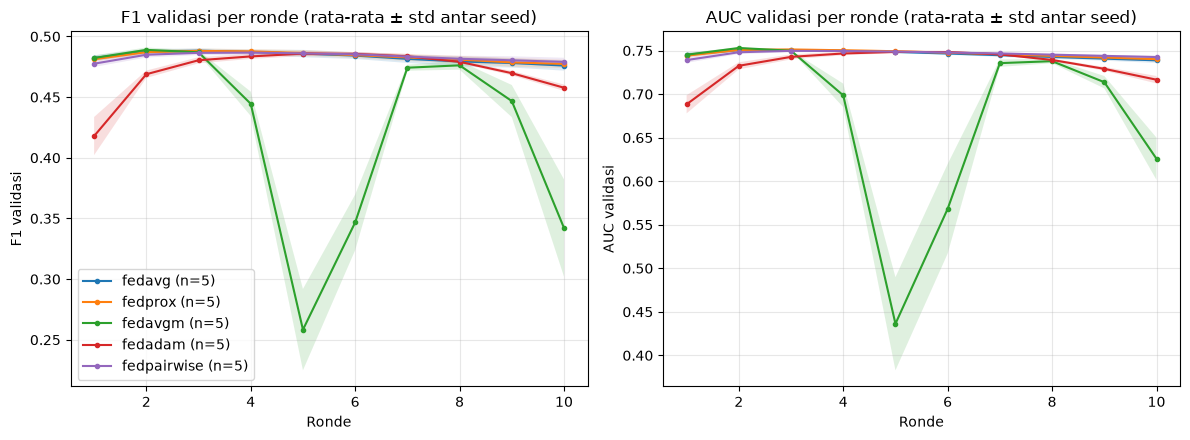

Grafik disimpan: C:\Users\s2\Documents\FIXRKI\FIXbanget\baselinefed\kurva_roc_pr_test.png


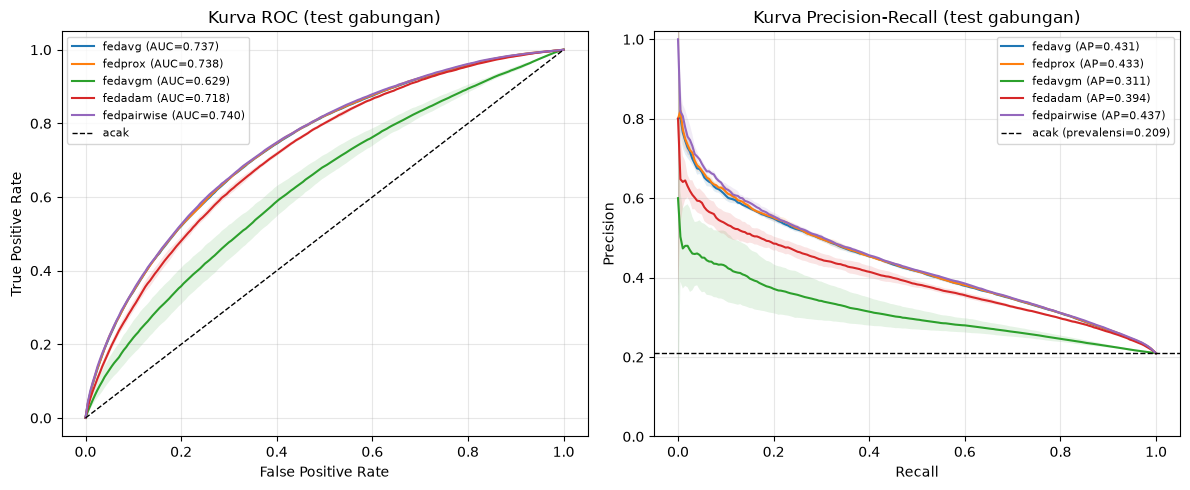

In [3]:
# ============================================================
# 4. ENTRY POINT  (guard wajib untuk Ray/multiprocessing di Windows)
# ============================================================
def main(argv=None):
    ap = argparse.ArgumentParser(description="Simulasi Federated Learning")
    ap.add_argument('--algo', default=None, choices=ALGOS,
                    help="jalankan satu algoritma saja (tanpa komparasi)")
    ap.add_argument('--compare', action='store_true',
                    help="komparasi (default bila --algo tidak diberikan)")
    ap.add_argument('--algos', nargs='+', choices=ALGOS, default=ALGOS,
                    help="daftar algoritma untuk komparasi")
    ap.add_argument('--seeds', nargs='+', type=int, default=None,
                    help="timpa SEEDS di atas, mis. --seeds 0 1 2 3 4 (opsional)")
    ap.add_argument('--info', action='store_true',
                    help="hanya tampilkan ringkasan data")
    args, _ = ap.parse_known_args(argv)
 
    seeds = list(dict.fromkeys(args.seeds)) if args.seeds else list(dict.fromkeys(SEEDS))
 
    show_modules()
    setup_dataset()
    n_clients = data_summary()
    if args.info:
        return
 
    out_root = ORIG_OUT_DIR.parent
 
    if args.algo and not args.compare:
        run_single(args.algo, seeds, n_clients, out_root)
    else:
        run_compare(available_algos(args.algos), seeds, n_clients, out_root)
 
 
if __name__ == '__main__':
    main()